In [1]:
! source /home/jupyter-r.yazdi/myproject/ryazdi/dti3d/bin/activate

In [2]:
import os
import shutil
#shutil.rmtree('dataset')
#! unzip 'BUSBRA.zip'

In [3]:
ROOT = '/home/jupyter-r.yazdi/myproject/ryazdi/dti3d/0pycodes/UnetMaxsig/BUSBRA/'
config = {
    "lr": 1e-4,
    "batch_size": 8,
    "epochs": 150,
    }

In [4]:
from time import perf_counter
import numpy as np
import cv2
import matplotlib.pyplot as plt

import os
from glob import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torchvision import transforms
import torchvision.transforms.functional as TF
from torchvision.utils import make_grid
from PIL import Image

from torch.optim.lr_scheduler import StepLR
from torch.utils.data import DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

/home/jupyter-r.yazdi/.local/lib/python3.10/site-packages/albumentations/__init__.py:13: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.18). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


In [5]:
#dataset
from torch.utils.data import Dataset
class mydataset(Dataset):
    def __init__(self,images_dir,masks_dir,transforms_img=None):
        self.images_dir=images_dir
        self.masks_dir=masks_dir
        self.transforms_img=transforms_img
        self.mask_names= glob(masks_dir + "*.png")

    def __len__(self):
        return len(self.mask_names)

    def __getitem__(self,index):
        mask_name=self.mask_names[index]
        mask=cv2.imread(mask_name,cv2.IMREAD_ANYDEPTH)
        mask = (mask - mask.min()) / (mask.max() - mask.min())#ejbari
        mask= (mask>0).astype(np.float32)
        mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_AREA)

        imgn=mask_name.replace('/masks/','/images/').replace('/mask_','/bus_')
              
        image=cv2.imread(imgn,cv2.IMREAD_ANYDEPTH)
        image = (image - image.min()) / (image.max() - image.min()).astype(np.float32)#ejbari
        image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_AREA)

        if self.transforms_img is not None:
            transformed = self.transforms_img(image=image, mask=mask)
            image = transformed["image"]
            mask = transformed["mask"]

        return image, mask

In [6]:
#train dataset

images_dir= ROOT + 'dataset/train/images/'
masks_dir= ROOT + 'dataset/train/masks/'
batch_size=config['batch_size']
shuffle=True

train_transform = A.Compose([

    #A.RandomCrop(256,256,always_apply=True, p=1.0),
    #A.UnsharpMask (blur_limit=(3, 5), sigma_limit=0, alpha=(0.2, 0.5), threshold=10, always_apply=False, p=0.1),
    #A.RandomGamma (gamma_limit=(80, 150), always_apply=False, p=0.1),
    #A.RandomBrightnessContrast (brightness_limit=0.2, contrast_limit=0.5, brightness_by_max=True, always_apply=False, p=0.25),
    #A.PadIfNeeded (min_height=1048, min_width=790, border_mode=cv2.BORDER_CONSTANT, value=0,always_apply=True, p=1.0),

    #A.Resize(256,256),
    ToTensorV2()])


train_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=train_transform)
print("number of loaded training images: ",train_ds.__len__())

train_dataset = DataLoader(train_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(train_dataset), "training batches.")

number of loaded training images:  1312
loaded 164 training batches.


In [7]:
#val dataset

images_dir= ROOT + 'dataset/val/images/'
masks_dir= ROOT + 'dataset/val/masks/'
batch_size=config['batch_size']
shuffle=True

val_transform = A.Compose([

    #A.PadIfNeeded (min_height=790, min_width=790, border_mode=cv2.BORDER_CONSTANT, value=0,always_apply=True,  p=1.0),
    #A.Resize(256,256),
    ToTensorV2()])

val_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=val_transform)
print("number of loaded val images: ",val_ds.__len__())

val_dataset = DataLoader(val_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(val_dataset), "validation batches.")

number of loaded val images:  281
loaded 36 validation batches.


data_batch.size= torch.Size([8, 1, 256, 256])
mask.size= torch.Size([8, 1, 256, 256])


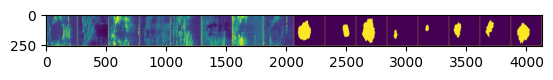

In [8]:

#data_batch, labels_batch = next(iter(train_dataset))
data_batch, mask= next(iter(train_dataset))

print('data_batch.size=',data_batch.size())
mask=mask.unsqueeze(1)
print('mask.size=',mask.size())
#crn=corner_response_map(data_batch)
tmp=torch.cat((data_batch, mask),0)
grid= make_grid(tmp,nrow=1,pad_value=1)
grid=grid.to('cpu')[1,...]
plt.imshow(grid.numpy().transpose((1, 0)))


In [9]:
#from skimage.filters import threshold_isodata

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)

class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, features=[64, 128, 256, 512]):
        super(UNet, self).__init__()
        self.ups = nn.ModuleList()
        self.downs = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Down part of UNET
        for feature in features:
            self.downs.append(DoubleConv(in_channels, feature))
            in_channels = feature

        # Up part of UNET
        for feature in reversed(features):
            self.ups.append(
                nn.ConvTranspose2d(
                    feature * 2, feature, kernel_size=2, stride=2,
                )
            )
            self.ups.append(DoubleConv(feature * 2, feature))

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)
        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skip_connections = []

        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1] # Reverse the list

        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x)
            skip_connection = skip_connections[idx//2]

            if x.shape != skip_connection.shape:
                x = TF.resize(x, size=skip_connection.shape[2:])

            concat_skip = torch.cat((skip_connection, x), dim=1)
            x = self.ups[idx+1](concat_skip)

        return self.final_conv(x)


In [10]:
torch.manual_seed(42)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

data_batch,mask_name = next(iter(train_dataset))
print("data_batch.size=",data_batch.size())

model=UNet().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model.parameters(),lr=1e-4)

scheduler = StepLR(optimizer, step_size=100, gamma=0.83)
scaler = torch.amp.GradScaler('cuda')

best_valid_dice=0
best_epoch=0
train_loss_plot=[]
val_loss_plot=[]
val_dice_plot=[]
last_lr=scheduler.get_last_lr()

for epoch in range(config['epochs']):

    if(last_lr != scheduler.get_last_lr()):
        print(80*'-')
        #net.load_state_dict(torch.load('f:/pred_img/best-model.pt'))
        print(f'The lr changed from {last_lr} to {scheduler.get_last_lr()}. thus previous best model loaded!')
        last_lr = scheduler.get_last_lr()

    print("\r\nepoch ",epoch+1," started!",' LR=', last_lr)

    t_start = perf_counter()

    #model training step
    running_loss = 0.0
    model.train()
    for inputs,mask in train_dataset:

        optimizer.zero_grad()
        with torch.autocast(device_type="cuda"):
            outputs = model(inputs.to(device))
            labels=mask.to(device).unsqueeze(1)
            loss = criterion(outputs, labels)

        running_loss += loss.item()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

    ep_loss=running_loss / len(train_dataset)
    print("train_loss: " ,ep_loss)
    train_loss_plot.append(ep_loss)
    scheduler.step()

    #model evaluation step
    dice_score = 0
    val_loss = 0.0
    with torch.no_grad():
        model.eval()
        for inputs,mask in val_dataset:

            inputs=inputs.to(device)
            preds =model(inputs)
            labels=mask.to(device).unsqueeze(1)
            loss = criterion(preds, labels)
            val_loss += loss.item()

            pred_sig=torch.sigmoid(preds)

            preds=(pred_sig>0.5).float()
            intersection=(preds * labels).sum()
            union=(preds + labels).sum()
            dice_score += (2 * intersection / union)

    ep_loss=val_loss / len(val_dataset)
    print("val_loss: " ,ep_loss)
    val_loss_plot.append(ep_loss)
    epoch_dc= float(dice_score/len(val_dataset))
    val_dice_plot.append(epoch_dc)
    print(f"Validation_Dice Score = {epoch_dc:.12f}")
    if(best_valid_dice< epoch_dc):
        best_valid_dice=epoch_dc
        best_epoch=epoch
        torch.save(model.state_dict(), 'best-model-unet.pt')
        print('The best model saved...')
        #tmp=torch.cat((labels,preds),0)
        #grid= make_grid(tmp,nrow=6,pad_value=1)
        #torchvision.utils.save_image(grid, f"f:/pred_img/sim/all/{epoch+1}.tif")

    print('Best validation dice=',best_valid_dice, ' in epoch ', best_epoch+1)
    #print(net.m1.weight.detach().cpu().numpy())
    print(f"Epoch finished in {perf_counter()-t_start} seconds.\r\n")


data_batch.size= torch.Size([8, 1, 256, 256])

epoch  1  started!  LR= [0.0001]
train_loss:  0.42320642638497236
val_loss:  0.31883225507206386
Validation_Dice Score = 0.660964429379
The best model saved...
Best validation dice= 0.6609644293785095  in epoch  1
Epoch finished in 14.53143742121756 seconds.


epoch  2  started!  LR= [0.0001]
train_loss:  0.28241355308308835
val_loss:  0.2546534546547466
Validation_Dice Score = 0.739535212517
The best model saved...
Best validation dice= 0.7395352125167847  in epoch  2
Epoch finished in 14.87625339301303 seconds.


epoch  3  started!  LR= [0.0001]
train_loss:  0.22258107618587772
val_loss:  0.2122348149617513
Validation_Dice Score = 0.767038643360
The best model saved...
Best validation dice= 0.7670386433601379  in epoch  3
Epoch finished in 14.817498417105526 seconds.


epoch  4  started!  LR= [0.0001]
train_loss:  0.18546824229926598
val_loss:  0.16674772401650748
Validation_Dice Score = 0.825944006443
The best model saved...
Best valida

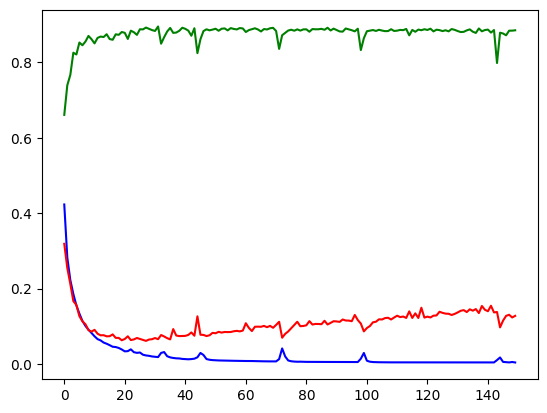

In [11]:
plt.plot(train_loss_plot, color='blue',label='train_loss')
plt.plot(val_loss_plot, color='red',label='val_loss')
plt.plot(val_dice_plot ,color='green',label='val_dice')
plt.show()

In [12]:
#test dataset

images_dir= ROOT + 'dataset/test/images/'
masks_dir= ROOT + 'dataset/test/masks/'
batch_size=config['batch_size']
shuffle=True

test_transform = A.Compose([

    #A.PadIfNeeded (min_height=790, min_width=790, border_mode=cv2.BORDER_CONSTANT, value=0,always_apply=True,  p=1.0),
    #A.Resize(256,256),
    ToTensorV2()])

test_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=test_transform)
print("number of loaded test images: ",test_ds.__len__())

test_dataset = DataLoader(test_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(test_dataset), "test batches.")

number of loaded test images:  282
loaded 36 test batches.


In [13]:
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---- Binary semantic segmentation example ----
model=UNet().to(device)
#model evaluation step
dice_score = 0
model.load_state_dict(torch.load('best-model-unet.pt'))
with torch.no_grad():
    model.eval()
    for inputs,mask in test_dataset:

        inputs=inputs.to(device)
        preds =model(inputs)
        labels=mask.to(device).unsqueeze(1)        
        pred_sig=torch.sigmoid(preds)
        preds=(pred_sig>0.5).float()
        intersection=(preds * labels).sum()
        union=(preds + labels).sum()
        dice_score += (2 * intersection / union)

epoch_dc= float(dice_score/len(test_dataset))

print(f"test Dice Score = {epoch_dc:.12f}")


test Dice Score = 0.866891562939
